# Data Characterization and Exploratory Data Analysis

The objective of this notebook is to characterize the **raw data** for Lisbon and Porto: Airbnb listings and reviews, OpenStreetMap (OSM) points of interest (POIs), and Wikipedia articles linked to POIs. It focuses on dataset size, data quality, key distributions, text characteristics and spatial coverage. Detailed tables are exported to CSV and selected figures to PDF.

**Scope:** the final processed documents and cross-source integration are evaluated in later pipeline stages. Language detection below is a lightweight heuristic, so language estimates should be treated as indicative rather than definitive.

**How to run:** keep the raw files under `data/raw/` as described in the project README. The notebook searches the current directory and its parents for that folder.

## 1. Setup and helper functions

Each data source is analysed separately, focusing on its main characteristics, data quality and potential limitations.

In [1]:
from pathlib import Path
import html
import os
import json
import re
from collections import Counter

os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
candidates = [Path.cwd().resolve()] + list(Path.cwd().resolve().parents)
ROOT = next((p for p in candidates if (p / "data" / "raw").exists()), candidates[0])
RAW = ROOT / "data" / "raw"
FIGURES = ROOT / "analysis" / "figures"
TABLES = ROOT / "analysis" / "tables"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

CITIES = ["lisboa", "porto"]
PRICE_MAX = 1000  # analytical cut-off for price plots; not a data-cleaning operation
SAMPLE_SIZE = 3000
REVIEW_SAMPLE_FRAC = 0.02
SEED = 0

required = ([RAW / f"airbnb_{city}" / name for city in CITIES
             for name in ["listings.csv.gz", "reviews.csv.gz", "neighbourhoods.geojson"]]
            + [RAW / "osm" / f"pois_{city}.json" for city in CITIES]
            + [RAW / "wikipedia" / "articles.jsonl"])
missing = [str(p) for p in required if not p.exists()]
assert not missing, "Missing required data files: " + ", ".join(missing)
print(f"Project root: {ROOT}")
print(f"Raw data directory: {RAW}")

TAG_RE = re.compile(r"<[^>]+>")
WORD_RE = re.compile(r"[^\W\d_]+")
STOPWORDS = set("""
a as ao aos à às o os de da das do dos e é em no na nos nas num numa um uma uns umas por para com sem que se seu sua seus suas mais menos ou como este esta isto isso são ser foi há tem não nao muito também ficar
el la los las y en un una unos unas por para con sin que su sus del al lo es son fue
le les des du et au aux un une pour avec sans qui dans sur sont
the and of to in on for from this that is are was were an by or be it its you your we our
der die das und ist mit von zu im den
""".split())

def clean_text(value):
    text = html.unescape(TAG_RE.sub(" ", str(value)))
    return re.sub(r"\s+", " ", text).strip()

def tokens(text):
    return [t for t in WORD_RE.findall(text.lower()) if len(t) > 2 and t not in STOPWORDS]

def term_counts(texts):
    counter = Counter()
    for text in texts:
        counter.update(tokens(text))
    return counter

_MARKERS = {
    "pt": {"que", "não", "uma", "para", "com", "dos", "das", "muito", "casa", "está"},
    "en": {"the", "and", "with", "for", "from", "that", "this", "you", "very", "was"},
    "es": {"el", "los", "las", "una", "con", "para", "muy", "está", "del", "casa"},
    "fr": {"le", "les", "des", "une", "avec", "pour", "très", "est", "dans", "appartement"},
}
def detect_lang(text):
    words = set(WORD_RE.findall(text.lower()))
    scores = {lang: len(words & markers) for lang, markers in _MARKERS.items()}
    best = max(scores, key=scores.get)
    return best if scores[best] > 0 else "unknown"

def language_distribution(texts):
    counts = Counter(detect_lang(text) for text in texts if text)
    total = sum(counts.values())
    return {lang: count / total for lang, count in counts.most_common()} if total else {}

def file_mb(path):
    return round(path.stat().st_size / 1024**2, 2)

Project root: /home/joanadcarvalhal/pri/PRI_projeto
Raw data directory: /home/joanadcarvalhal/pri/PRI_projeto/data/raw


## 2. Dataset overview and Airbnb listings

The collection combines tabular, textual and spatial data. Listings and reviews are analysed separately because they have different units of observation: one record per accommodation in the listings files and one record per review in the reviews files. OSM and Wikipedia are evaluated as POI-oriented sources, with attention to identifiers, coordinates, names and links that can support later integration.

In [2]:
listings = {}
for city in CITIES:
    path = RAW / f"airbnb_{city}" / "listings.csv.gz"
    listings[city] = pd.read_csv(path, compression="gzip")
    print(f"{city.title()}: {len(listings[city]):,} listings, {listings[city].shape[1]} fields")

listing_overview = pd.DataFrame([
    {"city": city, "records": len(df), "fields": df.shape[1],
     "duplicate_rows": int(df.duplicated().sum()),
     "duplicate_ids": int(df["id"].duplicated().sum()) if "id" in df else np.nan}
    for city, df in listings.items()
])
display(listing_overview)
listing_overview.to_csv(TABLES / "airbnb_listing_overview.csv", index=False)

# Missing values
missing_tables = {}
for city, df in listings.items():
    table = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_pct": (df.isna().mean() * 100).round(2),
        "dtype": df.dtypes.astype(str),
        "distinct_non_null": df.nunique(dropna=True),
    }).sort_values("missing_pct", ascending=False)
    missing_tables[city] = table
    table.to_csv(TABLES / f"airbnb_missing_values_{city}.csv")
    print(f"Most incomplete Airbnb fields — {city.title()}")
    display(table[table["missing_count"] > 0].head(12))

Lisboa: 24,876 listings, 90 fields
Porto: 15,278 listings, 90 fields


,city,records,fields,duplicate_rows,duplicate_ids
0,lisboa,24876,90,0,0
1,porto,15278,90,0,0


Most incomplete Airbnb fields — Lisboa


,missing_count,missing_pct,dtype,distinct_non_null
neighborhood_overview,24876,100.0,float64,0
host_since,24876,100.0,float64,0
host_response_time,24876,100.0,float64,0
host_thumbnail_url,24876,100.0,float64,0
host_acceptance_rate,24876,100.0,float64,0
host_response_rate,24876,100.0,float64,0
host_verifications,24876,100.0,float64,0
neighbourhood,24876,100.0,float64,0
host_total_listings_count,24876,100.0,float64,0
host_neighbourhood,24876,100.0,float64,0


Most incomplete Airbnb fields — Porto


,missing_count,missing_pct,dtype,distinct_non_null
neighborhood_overview,15278,100.0,float64,0
host_since,15278,100.0,float64,0
host_response_time,15278,100.0,float64,0
host_thumbnail_url,15278,100.0,float64,0
host_acceptance_rate,15278,100.0,float64,0
host_response_rate,15278,100.0,float64,0
host_verifications,15278,100.0,float64,0
neighbourhood,15278,100.0,float64,0
host_total_listings_count,15278,100.0,float64,0
host_neighbourhood,15278,100.0,float64,0


## 3. Airbnb data quality and key distributions

For Airbnb listings, quality checks cover missingness, duplicate rows and IDs, price validity, coordinate completeness, accommodation type and description availability. These checks identify limitations that should be handled explicitly in later stages of the project.

Not all unusual values necessarily represent errors. In particular, high prices are retained in the raw data and only flagged for inspection; the price plots use a documented analytical cut-off to keep the main distribution readable.

,city,missing_or_nonpositive,positive_prices,prices_above_1000,pct_positive_prices_above_cutoff,median_positive_price,p95_positive_price
0,lisboa,2240,22636,233,1.03,136.0,442.0625
1,porto,1592,13686,53,0.39,118.0,337.0000


,city,missing_latitude,missing_longitude,invalid_coordinate_pairs
0,lisboa,0,0,0
1,porto,0,0,0


,city,field,empty_count,empty_pct,median_words,p95_words
0,lisboa,name,0,0.00,6.0,9.0
1,lisboa,description,613,2.46,66.0,87.0
2,porto,name,0,0.00,6.0,9.0
3,porto,description,309,2.02,64.0,86.0


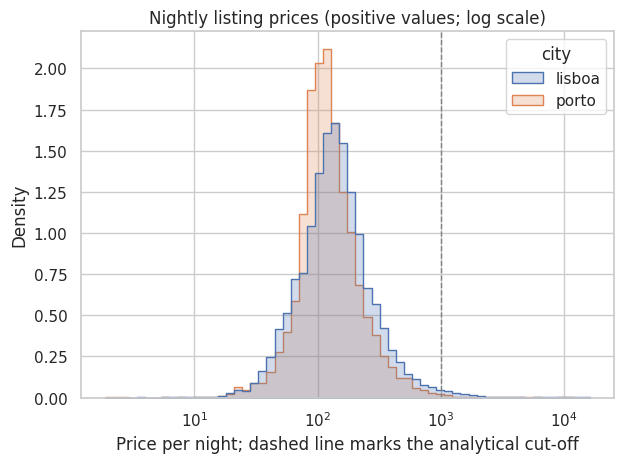

,city,room_type,listings
0,lisboa,Entire home/apt,18444
1,lisboa,Hotel room,153
2,lisboa,Private room,6131
3,lisboa,Shared room,148
4,porto,Entire home/apt,12800
5,porto,Hotel room,79
6,porto,Private room,2268
7,porto,Shared room,131


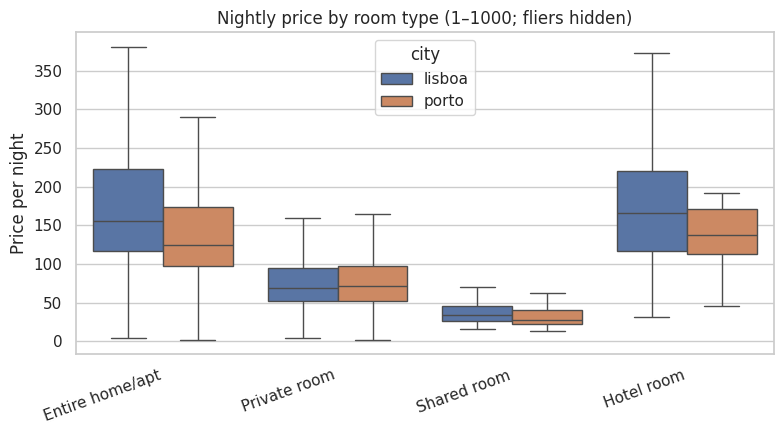

In [3]:
def parse_price(series):
    return (series.astype("string").str.replace(r"[$€,]", "", regex=True)
            .str.replace(r"\s+", "", regex=True)
            .replace(["", "nan", "<NA>"], np.nan).astype(float))

price_rows, coordinate_rows, text_rows = [], [], []
for city, df in listings.items():
    df["price_numeric"] = parse_price(df["price"])
    df["price_capped"] = df["price_numeric"].where(df["price_numeric"].between(1, PRICE_MAX))
    p = df["price_numeric"]
    positive = p.gt(0)
    price_rows.append({
        "city": city, "missing_or_nonpositive": int((~positive).sum()),
        "positive_prices": int(positive.sum()),
        f"prices_above_{PRICE_MAX}": int((positive & p.gt(PRICE_MAX)).sum()),
        "pct_positive_prices_above_cutoff": round(100 * (positive & p.gt(PRICE_MAX)).sum() / max(positive.sum(), 1), 2),
        "median_positive_price": p[positive].median(),
        "p95_positive_price": p[positive].quantile(.95),
    })
    lat = pd.to_numeric(df.get("latitude"), errors="coerce")
    lon = pd.to_numeric(df.get("longitude"), errors="coerce")
    invalid_coords = lat.notna() & lon.notna() & (~lat.between(-90, 90) | ~lon.between(-180, 180))
    coordinate_rows.append({"city": city, "missing_latitude": int(lat.isna().sum()),
                            "missing_longitude": int(lon.isna().sum()),
                            "invalid_coordinate_pairs": int(invalid_coords.sum())})
    for field in ["name", "description"]:
        raw = df[field].fillna("").astype(str) if field in df else pd.Series([""] * len(df))
        cleaned = raw.map(clean_text)
        lengths = cleaned.str.split().str.len()
        text_rows.append({"city": city, "field": field, "empty_count": int(cleaned.eq("").sum()),
                          "empty_pct": round(100 * cleaned.eq("").mean(), 2),
                          "median_words": float(lengths.median()), "p95_words": float(lengths.quantile(.95))})

price_quality = pd.DataFrame(price_rows)
coordinate_quality = pd.DataFrame(coordinate_rows)
listing_text_metrics = pd.DataFrame(text_rows)
display(price_quality)
display(coordinate_quality)
display(listing_text_metrics)
price_quality.to_csv(TABLES / "airbnb_price_quality.csv", index=False)
coordinate_quality.to_csv(TABLES / "airbnb_coordinate_quality.csv", index=False)
listing_text_metrics.to_csv(TABLES / "airbnb_text_metrics.csv", index=False)

# Price distribution
price_data = pd.concat([df.loc[df["price_numeric"].gt(0), ["price_numeric"]].assign(city=city)
                        for city, df in listings.items()], ignore_index=True)
sns.histplot(data=price_data, x="price_numeric", hue="city", bins=60, stat="density",
             common_norm=False, element="step", log_scale=True)
plt.axvline(PRICE_MAX, color="grey", linestyle="--", linewidth=1)
plt.title("Nightly listing prices (positive values; log scale)")
plt.xlabel("Price per night; dashed line marks the analytical cut-off")
plt.ylabel("Density")
plt.tight_layout()
plt.savefig(FIGURES / "airbnb_price_distribution.pdf", bbox_inches="tight")
plt.show()

# One comparison of price by room type; values above the cut-off are excluded from this plot only.
room_rows = []
for city, df in listings.items():
    if "room_type" in df:
        counts = df.groupby("room_type", dropna=False).size()
        room_rows.extend({"city": city, "room_type": str(kind), "listings": int(n)} for kind, n in counts.items())
room_counts = pd.DataFrame(room_rows)
display(room_counts)
room_counts.to_csv(TABLES / "airbnb_room_type_counts.csv", index=False)
plot_frames = [df[["room_type", "price_capped"]].assign(city=city) for city, df in listings.items() if "room_type" in df]
if plot_frames:
    room_plot = pd.concat(plot_frames, ignore_index=True).dropna(subset=["room_type", "price_capped"])
    plt.figure(figsize=(8, 4.5))
    sns.boxplot(data=room_plot, x="room_type", y="price_capped", hue="city", showfliers=False)
    plt.title(f"Nightly price by room type (1–{PRICE_MAX}; fliers hidden)")
    plt.xlabel("")
    plt.ylabel("Price per night")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.savefig(FIGURES / "airbnb_price_by_room_type.pdf", bbox_inches="tight")
    plt.show()

## 4. OpenStreetMap points of interest

OpenStreetMap POIs are grouped into broad categories such as transport, food and drink, public parking, shops, tourism and heritage, and leisure. The analysis checks whether each POI has usable coordinates, a name, or external Wikidata/Wikipedia identifiers. These attributes determine how reliably POIs can be mapped, described and linked to other sources.

,city,pois,duplicate_ids,missing_coordinates,missing_name,with_wikidata,with_wikipedia
0,lisboa,45150,0,0,20525,757,395
1,porto,38411,0,0,13406,441,257


,city,category,pois
3,lisboa,public parking,19031
0,lisboa,transport,12486
1,lisboa,food and drink,9222
4,lisboa,shops,1873
2,lisboa,tourism and heritage,1866
5,lisboa,leisure,672
10,porto,transport,14990
7,porto,public parking,12323
6,porto,food and drink,7083
9,porto,shops,1798


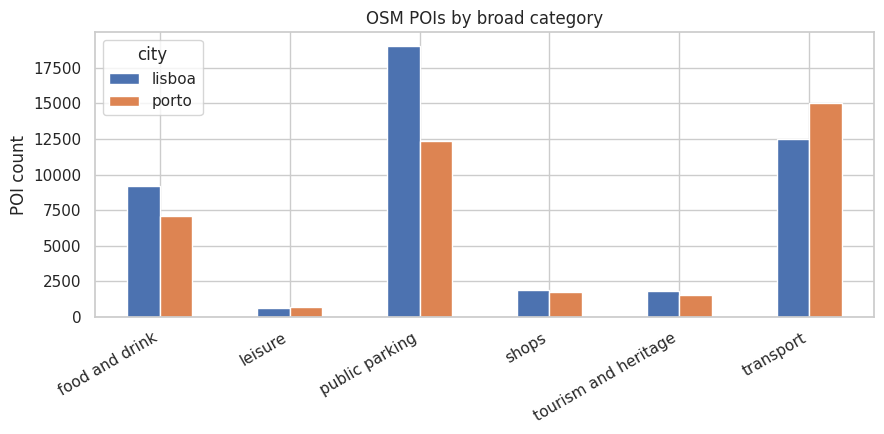

In [4]:
def osm_category(tags):
    if tags.get("highway") == "bus_stop" or tags.get("railway") == "station" or tags.get("station") == "subway":
        return "transport"
    if tags.get("amenity") in {"restaurant", "cafe", "bar", "pub", "fast_food", "ice_cream"}:
        return "food and drink"
    if tags.get("tourism") in {"attraction", "museum", "viewpoint", "gallery"} or tags.get("historic") in {"monument", "castle", "church", "memorial"}:
        return "tourism and heritage"
    if tags.get("shop") in {"supermarket", "bakery", "convenience"}:
        return "shops"
    if tags.get("leisure") in {"park", "beach_resort"} or tags.get("natural") == "beach":
        return "leisure"
    if tags.get("amenity") == "parking":
        return "public parking"
    return "other"

def osm_xy(element):
    """Return (latitude, longitude) for nodes or way/relation centres, if available."""
    if "lat" in element and "lon" in element:
        return element["lat"], element["lon"]
    centre = element.get("center") or {}
    if "lat" in centre and "lon" in centre:
        return centre["lat"], centre["lon"]
    return None

osm_elements, osm_category_rows, osm_quality_rows = {}, [], []
for city in CITIES:
    path = RAW / "osm" / f"pois_{city}.json"
    elements = json.loads(path.read_text(encoding="utf-8")).get("elements", [])
    osm_elements[city] = elements
    counts = Counter(osm_category(e.get("tags", {})) for e in elements)
    ids = [f"{e.get('type')}:{e.get('id')}" for e in elements]
    xy = [osm_xy(e) for e in elements]
    osm_quality_rows.append({
        "city": city, "pois": len(elements), "duplicate_ids": int(pd.Series(ids).duplicated().sum()),
        "missing_coordinates": sum(point is None for point in xy),
        "missing_name": sum(not str(e.get("tags", {}).get("name", "")).strip() for e in elements),
        "with_wikidata": sum(bool(e.get("tags", {}).get("wikidata")) for e in elements),
        "with_wikipedia": sum(bool(e.get("tags", {}).get("wikipedia")) for e in elements),
    })
    for category, count in counts.items():
        osm_category_rows.append({"city": city, "category": category, "pois": count})

osm_quality = pd.DataFrame(osm_quality_rows)
osm_categories = pd.DataFrame(osm_category_rows)
display(osm_quality)
display(osm_categories.sort_values(["city", "pois"], ascending=[True, False]))
osm_quality.to_csv(TABLES / "osm_quality.csv", index=False)
osm_categories.to_csv(TABLES / "osm_categories.csv", index=False)

category_plot = osm_categories.pivot(index="category", columns="city", values="pois").fillna(0)
category_plot.plot.bar(figsize=(9, 4.5), title="OSM POIs by broad category")
plt.ylabel("POI count")
plt.xlabel("")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(FIGURES / "osm_categories.pdf", bbox_inches="tight")
plt.show()

## 5. Spatial overview

The spatial figures show the broad distribution of listings and POIs in the two study areas. Coordinate completeness is checked before plotting, but the maps should be interpreted at city or neighbourhood scale rather than as exact representations of accommodation locations.

The Airbnb provider anonymizes listing coordinates. Maps are therefore used to inspect broad spatial patterns, not exact property locations.

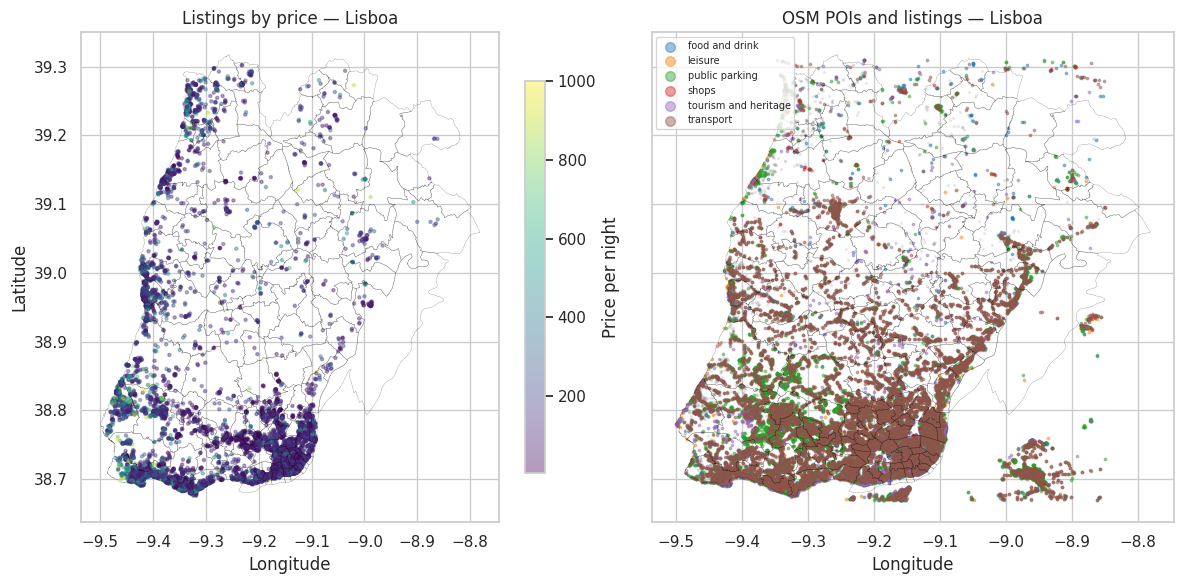

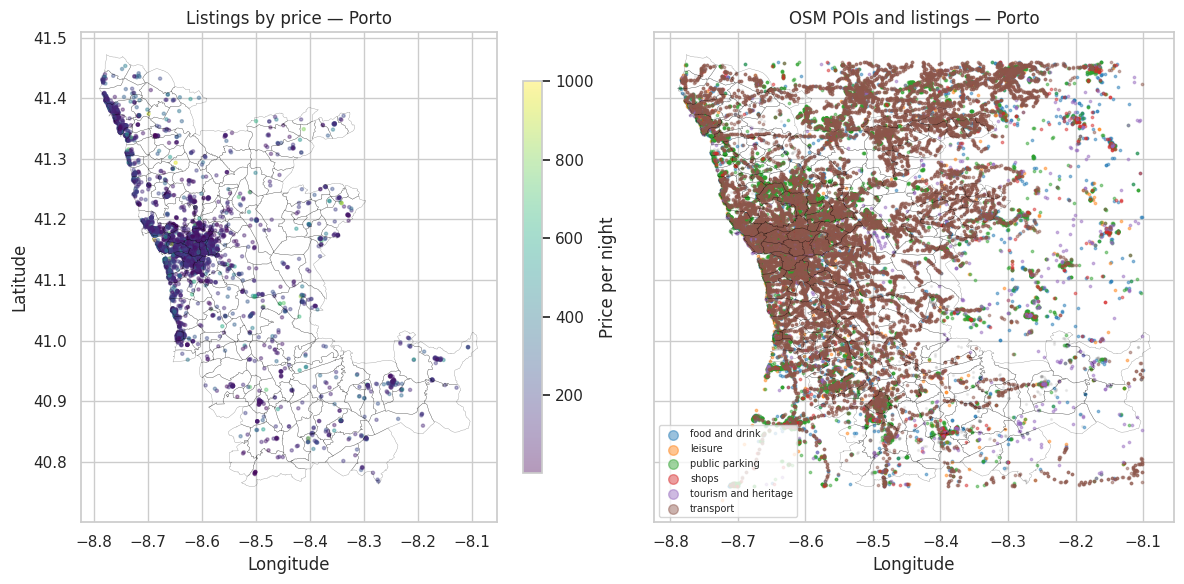

In [5]:
def draw_boundaries(ax, geojson):
    for feature in geojson.get("features", []):
        geometry = feature.get("geometry") or {}
        if geometry.get("type") == "Polygon":
            polygons = [geometry["coordinates"]]
        elif geometry.get("type") == "MultiPolygon":
            polygons = list(geometry["coordinates"])
        else:
            polygons = []
        for polygon in polygons:
            for ring in polygon:
                coordinates = np.asarray(ring)
                ax.plot(coordinates[:, 0], coordinates[:, 1], color="black", linewidth=.25, alpha=.45)

neighbourhood_geojson = {}
for city, df in listings.items():
    geojson = json.loads((RAW / f"airbnb_{city}" / "neighbourhoods.geojson").read_text(encoding="utf-8"))
    neighbourhood_geojson[city] = geojson
    map_data = df.dropna(subset=["latitude", "longitude", "price_capped"])
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6), sharex=True, sharey=True)
    draw_boundaries(ax1, geojson)
    points = ax1.scatter(map_data["longitude"], map_data["latitude"], c=map_data["price_capped"],
                         s=5, alpha=.4, cmap="viridis")
    fig.colorbar(points, ax=ax1, label="Price per night", shrink=.8)
    ax1.set_title(f"Listings by price — {city.title()}")
    draw_boundaries(ax2, geojson)
    ax2.scatter(map_data["longitude"], map_data["latitude"], s=2, alpha=.12, color="grey")
    palette = dict(zip(sorted({osm_category(e.get("tags", {})) for e in osm_elements[city]}),
                       sns.color_palette("tab10", 10)))
    by_category = {}
    for element in osm_elements[city]:
        point = osm_xy(element)
        category = osm_category(element.get("tags", {}))
        if point is not None and category != "other":
            by_category.setdefault(category, []).append(point)
    for category, points in sorted(by_category.items()):
        points = np.asarray(points)
        ax2.scatter(points[:, 1], points[:, 0], s=3, alpha=.45, color=palette[category], label=category)
    ax2.legend(markerscale=4, fontsize=7, loc="best")
    ax2.set_title(f"OSM POIs and listings — {city.title()}")
    for ax in (ax1, ax2): ax.set_xlabel("Longitude")
    ax1.set_ylabel("Latitude")
    fig.tight_layout()
    fig.savefig(FIGURES / f"spatial_overview_{city}.pdf", bbox_inches="tight")
    plt.show()

## 6. Wikipedia articles

Wikipedia is analysed as a smaller, POI-linked text source. The checks cover the number of articles, QID and title completeness, empty text, language, article length and the number of POIs associated with each article. These measures indicate how much descriptive text is available for later retrieval and ranking.

,articles,fields,languages,duplicate_qids,missing_qids,missing_titles,empty_articles,articles_without_poi,articles_with_multiple_pois,median_words,p95_words
0,787,7,2,3,0,0,0,0,35,353.0,1999.4


,lang,article_count,median_words,mean_words,max_words
0,en,16,371.5,384.562500,874
1,pt,771,349.0,599.281453,9162


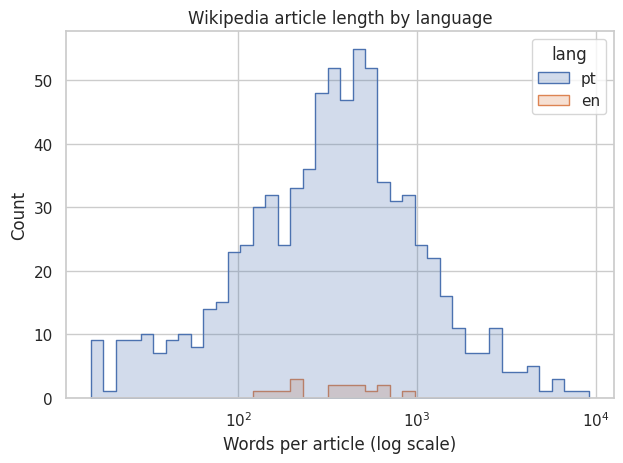

In [6]:
wiki_path = RAW / "wikipedia" / "articles.jsonl"
articles = []
with wiki_path.open(encoding="utf-8") as file:
    for line in file:
        if line.strip(): articles.append(json.loads(line))
wiki = pd.DataFrame(articles)
for column in ["text", "lang", "qid", "title", "pois"]:
    if column not in wiki: wiki[column] = None
wiki["text"] = wiki["text"].fillna("").astype(str)
wiki["num_chars"] = wiki["text"].str.len()
wiki["num_words"] = wiki["text"].str.split().str.len()
wiki["empty_text"] = wiki["text"].str.strip().eq("")
wiki["n_pois"] = wiki["pois"].apply(lambda value: len(value) if isinstance(value, list) else 0)

wiki_summary = pd.DataFrame([{
    "articles": len(wiki), "fields": len(articles[0]) if articles else 0,
    "languages": int(wiki["lang"].nunique(dropna=True)),
    "duplicate_qids": int(wiki["qid"].dropna().duplicated().sum()),
    "missing_qids": int(wiki["qid"].isna().sum()),
    "missing_titles": int(wiki["title"].isna().sum()),
    "empty_articles": int(wiki["empty_text"].sum()),
    "articles_without_poi": int(wiki["n_pois"].eq(0).sum()),
    "articles_with_multiple_pois": int(wiki["n_pois"].gt(1).sum()),
    "median_words": float(wiki["num_words"].median()) if len(wiki) else np.nan,
    "p95_words": float(wiki["num_words"].quantile(.95)) if len(wiki) else np.nan,
}])
wiki_by_language = wiki.groupby("lang", dropna=False)["num_words"].agg(article_count="count", median_words="median", mean_words="mean", max_words="max").reset_index()
display(wiki_summary)
display(wiki_by_language)
wiki_summary.to_csv(TABLES / "wikipedia_summary.csv", index=False)
wiki_by_language.to_csv(TABLES / "wikipedia_by_language.csv", index=False)
wiki[["qid", "lang", "title", "num_chars", "num_words", "empty_text", "n_pois"]].to_csv(TABLES / "wikipedia_article_metrics.csv", index=False)

if len(wiki):
    sns.histplot(data=wiki, x="num_words", hue="lang", bins=40, element="step", log_scale=(True, False))
    plt.title("Wikipedia article length by language")
    plt.xlabel("Words per article (log scale)")
    plt.tight_layout()
    plt.savefig(FIGURES / "wikipedia_article_lengths.pdf", bbox_inches="tight")
    plt.show()

## 7. Text characteristics of Airbnb descriptions and reviews

The text analysis examines both Airbnb listing descriptions and guest reviews. Listing names are present for all records and have a median length of six words in both cities. Descriptions are longer, with median lengths of 66 words in Lisbon and 64 words in Porto, but 613 Lisbon descriptions (2.46%) and 309 Porto descriptions (2.02%) are empty. The review files contain 1,886,932 Lisbon reviews and 1,131,143 Porto reviews. After cleaning, the mean review length is 44.58 words in Lisbon and 40.41 words in Porto. Language estimates are based on a documented sample and a marker-word heuristic, so they should be used as indicative information rather than as definitive language labels.

,city,descriptions,empty_descriptions,empty_pct,median_words,p95_words
0,lisboa,24876,613,2.46,66.0,87.0
1,porto,15278,309,2.02,64.0,86.0


,city,language,share,sample_size
0,lisboa,en,0.991000,3000
1,lisboa,unknown,0.006667,3000
2,lisboa,pt,0.002000,3000
3,lisboa,fr,0.000333,3000
4,porto,en,0.988333,3000
5,porto,unknown,0.009667,3000
6,porto,pt,0.001667,3000
7,porto,fr,0.000333,3000


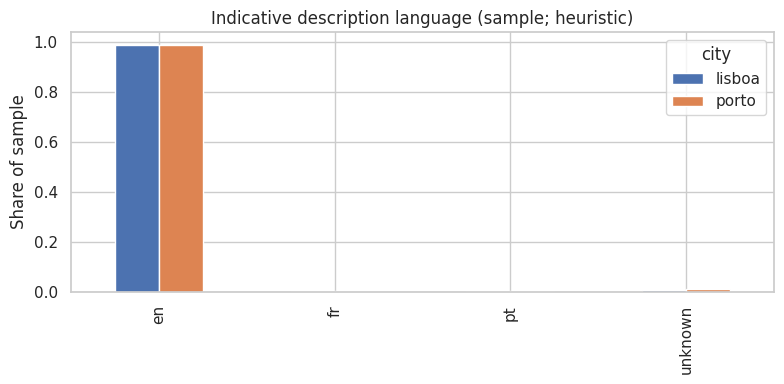

,city,reviews,null_comments,empty_comments_after_cleaning,empty_comment_pct,words,characters,mean_words_per_review,listings_with_reviews,listings_without_reviews,language_sample_size
0,lisboa,1886932,140,140,0.01,84120401,487749928,44.58,21794,3082,37796
1,porto,1131143,69,69,0.01,45715048,265820336,40.41,13683,1595,22584


,count,mean,std,min,25%,50%,75%,max
city,,,,,,,,
lisboa,21794.0,86.58,123.44,1.0,8.0,35.0,112.0,1931.0
porto,13683.0,82.67,115.74,1.0,9.0,35.0,108.0,1137.0


In [7]:
# Description length and indicative language distribution, based on a reproducible sample.
description_rows, language_rows = [], []
for city, df in listings.items():
    descriptions = df.get("description", pd.Series([""] * len(df))).fillna("").astype(str).map(clean_text)
    lengths = descriptions.str.split().str.len()
    description_rows.append({"city": city, "descriptions": len(descriptions),
                             "empty_descriptions": int(descriptions.eq("").sum()),
                             "empty_pct": round(100 * descriptions.eq("").mean(), 2),
                             "median_words": float(lengths.median()), "p95_words": float(lengths.quantile(.95))})
    nonempty = descriptions[descriptions.ne("")]
    sample = nonempty.sample(min(SAMPLE_SIZE, len(nonempty)), random_state=SEED).tolist()
    for language, share in language_distribution(sample).items():
        language_rows.append({"city": city, "language": language, "share": share, "sample_size": len(sample)})

description_metrics = pd.DataFrame(description_rows)
description_languages = pd.DataFrame(language_rows)
display(description_metrics)
display(description_languages.sort_values(["city", "share"], ascending=[True, False]))
description_metrics.to_csv(TABLES / "airbnb_description_metrics.csv", index=False)
description_languages.to_csv(TABLES / "airbnb_description_languages_heuristic.csv", index=False)
if not description_languages.empty:
    language_pivot = description_languages.pivot(index="language", columns="city", values="share").fillna(0)
    language_pivot.plot.bar(figsize=(8, 4), title="Indicative description language (sample; heuristic)")
    plt.ylabel("Share of sample")
    plt.xlabel("")
    plt.tight_layout()
    plt.savefig(FIGURES / "airbnb_description_languages.pdf", bbox_inches="tight")
    plt.show()

# Exact review counts and text metrics are accumulated in chunks to limit memory use.
review_rows, review_count_rows = [], []
for city in CITIES:
    path = RAW / f"airbnb_{city}" / "reviews.csv.gz"
    total = null_comments = empty_comments = total_words = total_chars = 0
    listing_counts = Counter()
    rng = np.random.default_rng(SEED)
    lang_sample = []
    for chunk in pd.read_csv(path, compression="gzip", usecols=["listing_id", "comments"], chunksize=100_000):
        raw_comments = chunk["comments"]
        null_comments += int(raw_comments.isna().sum())
        comments = raw_comments.fillna("").astype(str).map(clean_text)
        lengths = comments.str.split().str.len()
        total += len(comments)
        empty_comments += int(comments.eq("").sum())
        total_words += int(lengths.sum())
        total_chars += int(comments.str.len().sum())
        listing_counts.update(chunk["listing_id"].dropna().astype(str))
        if REVIEW_SAMPLE_FRAC > 0:
            mask = rng.random(len(comments)) < REVIEW_SAMPLE_FRAC
            lang_sample.extend(comments[mask & comments.ne("")].tolist())
    n_listings = len(listings[city])
    review_rows.append({"city": city, "reviews": total, "null_comments": null_comments,
                        "empty_comments_after_cleaning": empty_comments,
                        "empty_comment_pct": round(100 * empty_comments / max(total, 1), 2),
                        "words": total_words, "characters": total_chars,
                        "mean_words_per_review": round(total_words / max(total, 1), 2),
                        "listings_with_reviews": len(listing_counts),
                        "listings_without_reviews": n_listings - len(listing_counts),
                        "language_sample_size": len(lang_sample)})
    review_count_rows.extend({"city": city, "listing_id": listing_id, "reviews": count}
                             for listing_id, count in listing_counts.items())

review_metrics = pd.DataFrame(review_rows)
review_counts_by_listing = pd.DataFrame(review_count_rows)
display(review_metrics)
display(review_counts_by_listing.groupby("city")["reviews"].describe().round(2))
review_metrics.to_csv(TABLES / "airbnb_review_metrics.csv", index=False)
review_counts_by_listing.to_csv(TABLES / "airbnb_review_counts_by_listing.csv", index=False)

## 8. Combined source inventory and quality summary

The source inventory shows that the Airbnb data are the largest part of the collection. There are 24,876 listings in Lisbon and 15,278 in Porto, with 90 fields in each city. The corresponding review files contain 1,886,932 records for Lisbon and 1,131,143 for Porto. The OSM files contain 45,150 POIs for Lisbon and 38,411 for Porto, while the Wikipedia file contains 787 articles linked to POIs. These sources provide complementary information: listings describe accommodation, reviews provide user-generated text, OSM supplies structured spatial context, and Wikipedia provides longer descriptions for a smaller set of places.

The quality checks also reveal several concrete characteristics. Listing identifiers and complete rows are unique in both cities, and all listing records have valid latitude and longitude pairs. However, 2,240 Lisbon listings and 1,592 Porto listings have missing or non-positive prices. Descriptions are empty for 613 Lisbon listings (2.46%) and 309 Porto listings (2.02%). OSM records have no duplicate IDs or missing coordinates, but names are absent for 20,525 Lisbon POIs and 13,406 Porto POIs. Only 757 Lisbon POIs and 441 Porto POIs contain Wikidata identifiers, and Wikipedia identifiers are present for 395 and 257 POIs, respectively.

The review data are also unevenly distributed across listings. Reviews are available for 21,794 of the 24,876 Lisbon listings and for 13,683 of the 15,278 Porto listings. The mean review length is 44.58 words in Lisbon and 40.41 words in Porto, while 140 Lisbon comments and 69 Porto comments are null or empty after cleaning. For Wikipedia, all 787 articles have a QID, title and non-empty text; 771 are in Portuguese and 16 are in English. These results indicate that the data are sufficiently rich for further processing, although missing prices, incomplete metadata, uneven review coverage and heterogeneous OSM tagging must be considered.

In [8]:
source_rows = []
for city in CITIES:
    for source, filename, records, identifier in [
        ("Airbnb listings", "listings.csv.gz", len(listings[city]), "id"),
        ("Airbnb reviews", "reviews.csv.gz", int(review_metrics.loc[review_metrics.city.eq(city), "reviews"].iloc[0]), "listing_id (and review id if supplied)"),
    ]:
        path = RAW / f"airbnb_{city}" / filename
        fields = len(pd.read_csv(path, compression="gzip", nrows=0).columns)
        source_rows.append({"source": source, "city": city, "records": records, "fields": fields,
                            "file_mb_compressed": file_mb(path), "identifier": identifier})
    osm_path = RAW / "osm" / f"pois_{city}.json"
    source_rows.append({"source": "OSM POIs", "city": city, "records": len(osm_elements[city]),
                        "fields": np.nan, "file_mb_compressed": file_mb(osm_path), "identifier": "element type + id"})
source_rows.append({"source": "Wikipedia articles", "city": "all", "records": len(wiki),
                    "fields": len(articles[0]) if articles else 0,
                    "file_mb_compressed": file_mb(RAW / "wikipedia" / "articles.jsonl"), "identifier": "qid"})
source_summary = pd.DataFrame(source_rows)
display(source_summary)
source_summary.to_csv(TABLES / "source_summary.csv", index=False)

print("Key checks to review before downstream processing:")
print("• Airbnb: missing fields, duplicate IDs, invalid/missing prices, coordinate completeness and empty descriptions.")
print("• OSM: duplicate element IDs, missing coordinates/names, and availability of Wikidata/Wikipedia tags.")
print("• Wikipedia: duplicate/missing QIDs, missing titles, empty articles, language and length variation.")
print("• Reviews: missing/empty comments and uneven review counts across listings.")

,source,city,records,fields,file_mb_compressed,identifier
0,Airbnb listings,lisboa,24876,90.0,13.61,id
1,Airbnb reviews,lisboa,1886932,6.0,239.66,listing_id (and review id if supplied)
2,OSM POIs,lisboa,45150,NaN,13.44,element type + id
3,Airbnb listings,porto,15278,90.0,9.02,id
4,Airbnb reviews,porto,1131143,6.0,137.20,listing_id (and review id if supplied)
5,OSM POIs,porto,38411,NaN,11.52,element type + id
6,Wikipedia articles,all,787,7.0,3.06,qid


Key checks to review before downstream processing:
• Airbnb: missing fields, duplicate IDs, invalid/missing prices, coordinate completeness and empty descriptions.
• OSM: duplicate element IDs, missing coordinates/names, and availability of Wikidata/Wikipedia tags.
• Wikipedia: duplicate/missing QIDs, missing titles, empty articles, language and length variation.
• Reviews: missing/empty comments and uneven review counts across listings.


## 9. Summary and limitations

This EDA characterizes the raw collection before document processing and cross-source integration. The main results are that Lisbon has more Airbnb listings and reviews than Porto (24,876 versus 15,278 listings; 1,886,932 versus 1,131,143 reviews), while both cities have substantial OSM coverage (45,150 and 38,411 POIs). The Airbnb listing tables contain no duplicate IDs and no invalid coordinate pairs, but missing or non-positive prices affect 2,240 Lisbon records and 1,592 Porto records. OSM coordinates are complete, although names are missing for 45.5% of Lisbon POIs and 34.9% of Porto POIs. The review collection is large, but not every listing has reviews, and the average review is longer in Lisbon (44.58 words) than in Porto (40.41 words). Wikipedia is much smaller, with 787 articles, mostly in Portuguese (771 articles).

The following limitations should be considered when interpreting these results:

- Price values above the configured cut-off are flagged for distribution plots; they are not automatically errors and are not deleted from the raw data.
- Airbnb coordinates are anonymized by the provider, so spatial maps support broad pattern inspection only.
- OSM tagging is heterogeneous; a missing name or Wikidata/Wikipedia tag does not necessarily mean that a POI is invalid.
- Language proportions are based on a simple marker-word heuristic and a sample of descriptions; they are indicative only.
- Review counts and text length metrics are calculated across all records in chunks to limit memory use. Language analysis, where applicable, is based on samples.
- The datasets describe the collected snapshots and should not be interpreted as a complete census of all accommodation, POIs or relevant articles in Lisbon and Porto.
- The number of reviews is not a direct measure of listing quality or popularity, because review activity depends on listing age, booking volume and user behaviour.
- Missing values may reflect unavailable, suppressed or inapplicable fields rather than incorrect observations; therefore, they should be handled according to the requirements of each later processing stage.

The final processed documents, entity resolution and cross-source linking should be evaluated in their respective pipeline stages.